# 1. Research Question and Motivation
Is profitability concentrated among traders who consume relatively little order-book liquidity? Distinguish three questions: which groups generate aggregate **positive profits**, how unequally positive profits are distributed **within groups of profitable traders**, and whether lower-consumption traders have higher **profit per volume**.

Use total PnL for profit amounts and concentration, and PPV for relative profitability. Net PnL includes losses; positive-profit shares do not. Trader-level averages cannot show whether individual low-consumption trades were more profitable. Fewer levels consumed does not establish liquidity provision, maker/taker status, aggression, execution costs, or slippage.

# 2. Data Loading
Run from the folder containing `data_no_imputation.parquet`. Dependencies: pandas, NumPy, Matplotlib, SciPy, statsmodels, pyarrow (or another Parquet engine), and IPython/Jupyter. All state is created here; the source file is only read.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi':100,'axes.spines.top':False,'axes.spines.right':False})
df = pd.read_parquet("data_no_imputation.parquet")
print('Original dataset shape:',df.shape)
L,PNL,PPV='price_levels_per_transaction','trader_pnl','trader_ppv'
controls=['mean_tx_value','transactions_per_day','markets_per_day']
required=['trader',L,PNL,PPV,'transaction_count','trader_volume']+controls
missing=sorted(set(required)-set(df.columns))
if missing:
    raise ValueError(f'Missing required columns: {missing}')
print('All required columns exist.')
display(pd.DataFrame({'dtype':df[required].dtypes.astype(str),'missing':df[required].isna().sum()}))

Original dataset shape: (524760, 41)
All required columns exist.


,dtype,missing
trader,string,0
price_levels_per_transaction,float64,0
trader_pnl,float64,0
trader_ppv,float64,0
transaction_count,uint32,0
trader_volume,float64,0
mean_tx_value,float64,0
transactions_per_day,float64,0
markets_per_day,float64,0


# 3. Data Preparation
Create a separate working copy and verify unique trader identifiers. Duplicates are reported with their records and stop execution for investigation; no automatic aggregation or deletion occurs. The main sample requires finite liquidity, PnL, PPV, volume, and transaction count, with count ≥ 100. Control completeness is required only for regression. Preserve all extreme finite gains and losses. Positive-profit concentration selects profitable traders only when calculating that particular quantity.

In [2]:
working=df.copy(deep=True)
duplicated=working.trader.duplicated(keep=False)
print('Missing trader IDs:',int(working.trader.isna().sum()))
print('Rows with duplicated trader IDs:',int(duplicated.sum()))
if duplicated.any():
    display(working.loc[duplicated,required].sort_values('trader'))
if duplicated.any() or working.trader.isna().any():
    raise ValueError('Investigate trader identifiers before treating rows as unique traders.')
for col in required:
    if col!='trader': working[col]=pd.to_numeric(working[col],errors='raise')
core=[L,PNL,PPV,'transaction_count','trader_volume']
audits=[]
def sample_for(columns,threshold=100,label='Analysis'):
    cols=list(dict.fromkeys(['transaction_count']+list(columns)))
    eligible=working.transaction_count.ge(threshold)
    finite=np.isfinite(working[cols].to_numpy(dtype=float,na_value=np.nan)).all(axis=1)
    data=working.loc[eligible & finite,cols].copy()
    row={'analysis':label,'threshold':threshold,'original_n':len(working),'after_threshold':int(eligible.sum()),
         'invalid_removed':int((eligible & ~finite).sum()),'final_n':len(data)}
    audits.append(row); display(pd.DataFrame([row]))
    if data.empty: raise ValueError('Empty analysis sample.')
    return data
main=sample_for(core,label='Main sample')
sign_counts=pd.Series({'Positive PnL':int(main[PNL].gt(0).sum()),'Negative PnL':int(main[PNL].lt(0).sum()),'Zero PnL':int(main[PNL].eq(0).sum())})
display(pd.DataFrame({'n':sign_counts,'percent':100*sign_counts/len(main)}))

Missing trader IDs: 0
Rows with duplicated trader IDs: 0


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Main sample,100,524760,21323,0,21323


,n,percent
Positive PnL,8394,39.365943
Negative PnL,12886,60.432397
Zero PnL,43,0.201660


# 4. Descriptive Statistics
Report variable-specific finite counts within the main sample for descriptive controls, avoiding exclusions due to unrelated missing values. Histograms retain the full finite range. Skewness and upper percentiles reveal extreme observations; none are winsorized.

The liquidity column's name suggests a per-transaction measure, but available project files do not establish whether it counts all levels crossed, additional levels, or another quantity. Values below one and zeros call for caution. Use recorded proxy units; numeric construction alone does not establish economic meaning.

Zero / negative liquidity values: 1987 0


,count,mean,std,min,10%,25%,50%,75%,90%,99%,max,median,skewness
trader_pnl,21323.0,726.350952,3.340998e+04,-1.219870e+06,-3529.927417,-489.198832,-5.370294,125.470769,2398.965232,6.267729e+04,1.103256e+06,-5.370294,4.824136
trader_ppv,21323.0,-0.006120,5.411099e-02,-6.069192e-01,-0.048215,-0.018007,-0.001538,0.006262,0.030775,1.467419e-01,7.546843e-01,-0.001538,0.319841
price_levels_per_transaction,21323.0,0.008054,1.528256e-02,0.000000e+00,0.000002,0.000711,0.003722,0.009207,0.018729,7.432464e-02,3.179815e-01,0.003722,6.580563
transaction_count,21323.0,893.625756,6.023782e+03,1.000000e+02,109.000000,129.500000,199.000000,436.000000,1202.000000,1.168204e+04,4.194990e+05,199.000000,32.461046
trader_volume,21323.0,261244.639229,1.635295e+06,1.150648e+01,1229.963461,6730.999447,25043.996783,98113.007204,377552.715134,4.213445e+06,9.157941e+07,25043.996783,22.369458
mean_tx_value,21323.0,121.769645,2.601429e+02,1.745374e-02,4.537932,15.355537,51.324321,118.918250,289.020781,1.125636e+03,9.624208e+03,51.324321,9.589338


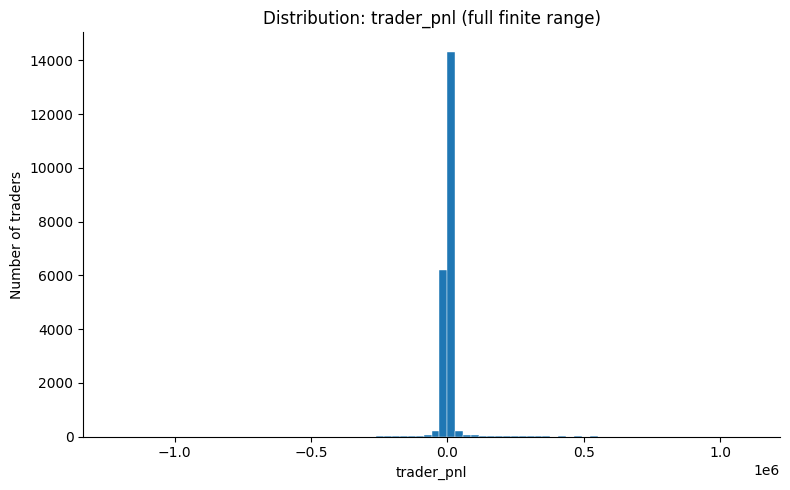

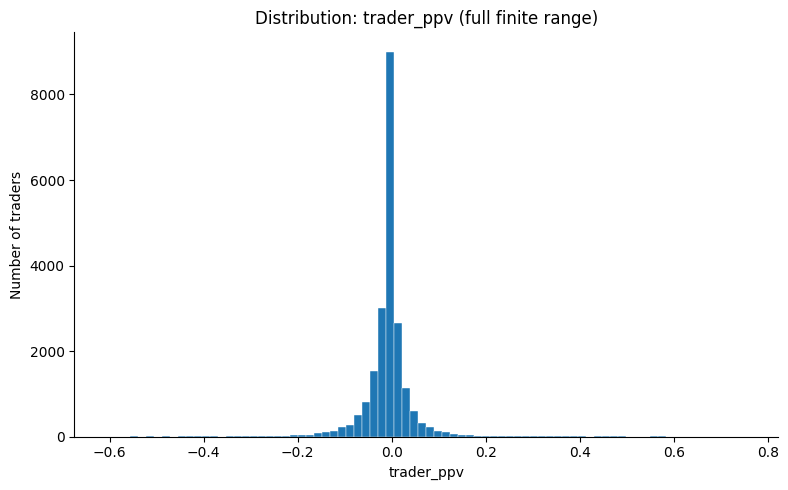

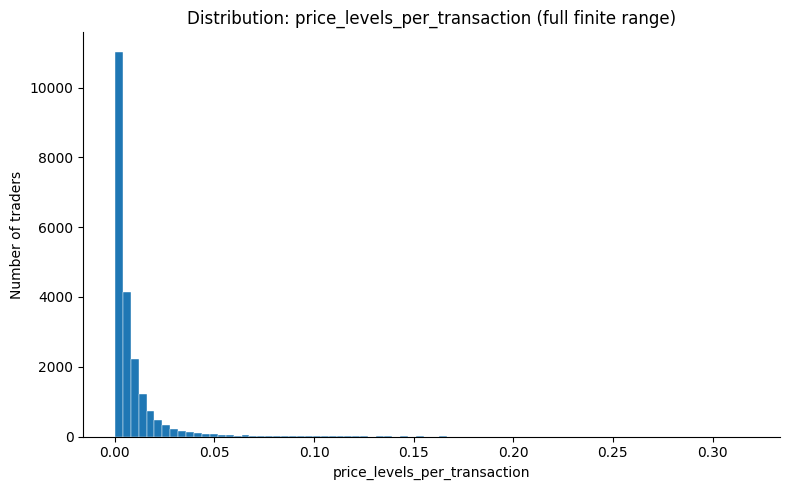

In [3]:
descriptive_columns=[PNL,PPV,L,'transaction_count','trader_volume','mean_tx_value']
descriptive=working.loc[main.index,descriptive_columns].replace([np.inf,-np.inf],np.nan)
summary=descriptive.describe(percentiles=[.1,.25,.5,.75,.9,.99]).T
summary['median']=descriptive.median(); summary['skewness']=descriptive.skew()
display(summary)
print('Zero / negative liquidity values:',int(main[L].eq(0).sum()),int(main[L].lt(0).sum()))
for col in [PNL,PPV,L]:
    fig,ax=plt.subplots(figsize=(8,5))
    ax.hist(main[col],bins=80,edgecolor='white',linewidth=.3)
    ax.set(title=f'Distribution: {col} (full finite range)',xlabel=col,ylabel='Number of traders')
    fig.tight_layout(); plt.show(); plt.close(fig)

# 5. Overall Profit Concentration
Sort positive-PnL traders by profit. For a requested top fraction f, use **ceil(f × number of profitable traders)**, with at least one trader when any are profitable. Report the actual selected count and fraction. Equal profits at a cutoff are interchangeable for the amount calculation; sensitivity exclusions later include all cutoff ties.

The Lorenz curve sorts positive profits in ascending order and includes (0,0) and (1,1). The Gini coefficient ranges from zero (equal profit amounts) toward one (high concentration); it is calculated only among positive-PnL traders. It is not a Gini of signed PnL or of all traders. With no profitable traders concentration is undefined; one profitable trader has Gini zero but provides no meaningful inequality comparison.

Profitable traders: 8394 ; positive-profit Gini: 0.9073233957097784
Aggregate positive profit: 70487371.22836553 ; net PnL: 15487981.344897771


,requested_top_percent,selected_n,actual_selected_percent,share_positive_profit_percent
0,0.1,9,0.107219,9.765282
1,1.0,84,1.000715,43.975077
2,5.0,420,5.003574,75.388238
3,10.0,840,10.007148,86.328641
4,20.0,1679,20.002383,94.461674


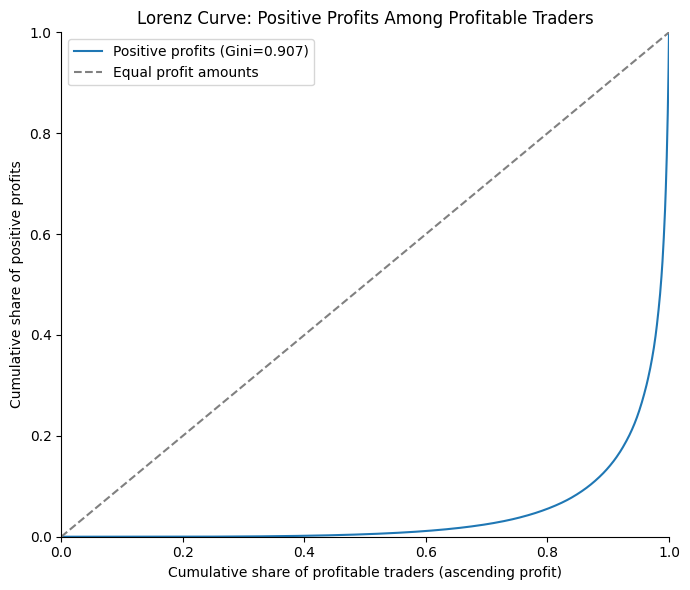

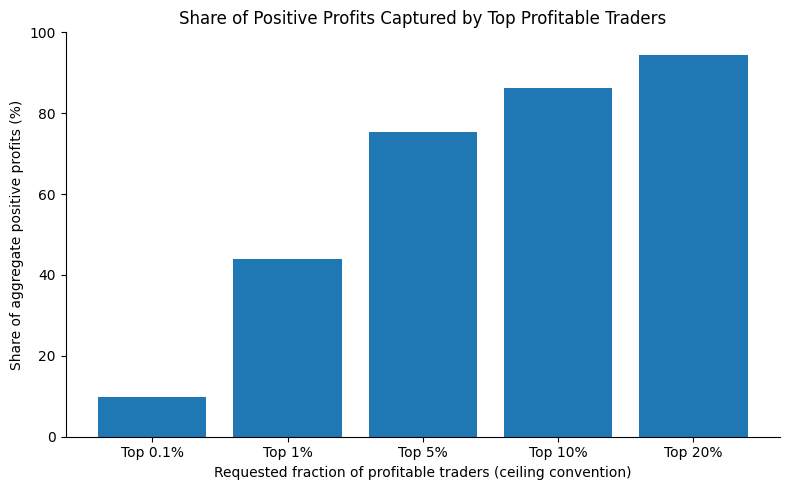

In [4]:
def positive_sorted(pnl):
    x=np.asarray(pnl,dtype=float)
    return np.sort(x[x>0])
def concentration(pnl,fractions=(.01,.1)):
    x=positive_sorted(pnl); n=len(x)
    result={'n_profitable':n,'positive_profit':float(x.sum()),'gini':np.nan}
    for f in fractions:
        result[f'top_{f:g}_share']=np.nan
        result[f'top_{f:g}_n']=0
    if n==0: return result
    scaled=x/x[-1]; total=scaled.sum()
    result['gini']=float(2*np.dot(np.arange(1,n+1),scaled)/(n*total)-(n+1)/n)
    for f in fractions:
        k=min(n,max(1,int(np.ceil(f*n))))
        result[f'top_{f:g}_share']=float(scaled[-k:].sum()/total)
        result[f'top_{f:g}_n']=k
    return result
def lorenz(pnl):
    x=positive_sorted(pnl)
    if len(x)==0: return None
    scaled=x/x[-1]
    return np.arange(len(x)+1)/len(x),np.r_[0,np.cumsum(scaled)/scaled.sum()]
fractions=[.001,.01,.05,.1,.2]
overall=concentration(main[PNL],fractions)
overall_table=pd.DataFrame([{'requested_top_percent':100*f,'selected_n':overall[f'top_{f:g}_n'],
    'actual_selected_percent':100*overall[f'top_{f:g}_n']/overall['n_profitable'] if overall['n_profitable'] else np.nan,
    'share_positive_profit_percent':100*overall[f'top_{f:g}_share']} for f in fractions])
display(overall_table)
print('Profitable traders:',overall['n_profitable'],'; positive-profit Gini:',overall['gini'])
print('Aggregate positive profit:',overall['positive_profit'],'; net PnL:',main[PNL].sum())
fig,ax=plt.subplots(figsize=(7,6))
curve=lorenz(main[PNL])
if curve is not None: ax.plot(*curve,label=f'Positive profits (Gini={overall["gini"]:.3f})')
ax.plot([0,1],[0,1],'--',color='gray',label='Equal profit amounts')
ax.set(xlim=(0,1),ylim=(0,1),title='Lorenz Curve: Positive Profits Among Profitable Traders',xlabel='Cumulative share of profitable traders (ascending profit)',ylabel='Cumulative share of positive profits')
ax.legend(); fig.tight_layout(); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(8,5))
ax.bar([f'Top {100*f:g}%' for f in fractions],overall_table.share_positive_profit_percent)
ax.set(ylim=(0,100),title='Share of Positive Profits Captured by Top Profitable Traders',xlabel='Requested fraction of profitable traders (ceiling convention)',ylabel='Share of aggregate positive profits (%)')
fig.tight_layout(); plt.show(); plt.close(fig)

# 6. Liquidity-Consumption Groups
Define quintiles once on **all main-sample traders**, including losses and zeros. Profitable-only analyses reuse these assignments. Duplicate boundaries are dropped; identical liquidity values are not arbitrarily separated. Report reduced group counts if five groups are infeasible. The first interval includes both endpoints; later intervals are left-open/right-closed.

In [5]:
def make_groups(data,label):
    result=data.copy()
    if data[L].nunique()==1:
        edges=np.array([data[L].iloc[0],data[L].iloc[0]])
        result['group']=pd.Categorical(['Q1']*len(data),categories=['Q1'],ordered=True)
    else:
        _,edges=pd.qcut(data[L],5,duplicates='drop',retbins=True)
        result['group']=pd.cut(data[L],edges,labels=[f'Q{i+1}' for i in range(len(edges)-1)],include_lowest=True)
    table=result.groupby('group',observed=False)[L].agg(observed_min='min',observed_max='max',n='size')
    table['lower_boundary']=edges[:-1]; table['upper_boundary']=edges[1:]
    print(f'{label}: {len(table)} groups.'+(' Repeated values prevent five distinct quintiles.' if len(table)<5 else ''))
    display(table)
    assert result.group.notna().all()
    return result,edges,table
main,group_edges,group_ranges=make_groups(main,'Main liquidity groups')
groups=list(main.group.cat.categories)
low,high=groups[0],groups[-1]
if len(groups)==5:
    group_names=dict(zip(groups,['Q1: Lowest','Q2: Low','Q3: Moderate','Q4: High','Q5: Highest']))
else:
    group_names={g:f'{g}: ascending consumption' for g in groups}
print('Group labels:',group_names)

Main liquidity groups: 5 groups.
Group labels: {'Q1': 'Q1: Lowest', 'Q2': 'Q2: Low', 'Q3': 'Q3: Moderate', 'Q4': 'Q4: High', 'Q5': 'Q5: Highest'}


,observed_min,observed_max,n,lower_boundary,upper_boundary
group,,,,,
Q1,0.000000,0.000311,4265,0.000000,0.000312
Q2,0.000312,0.002313,4264,0.000312,0.002314
Q3,0.002314,0.005403,4265,0.002314,0.005404
Q4,0.005404,0.011132,4264,0.005404,0.011136
Q5,0.011138,0.317981,4265,0.011136,0.317981


# 7. Profitability Across Liquidity Groups
Summaries include every trader. Positive profits sum gains; absolute losses sum the magnitudes of losses; net PnL equals positive profits minus absolute losses. PPV means and medians weight traders equally and are not the same as aggregate PnL divided by aggregate volume. The box plot shows all finite outliers.

,n,n_profitable,mean_pnl,median_pnl,net_pnl,positive_profit,absolute_losses,mean_ppv,median_ppv,total_volume,mean_volume,mean_count,median_count,profitable_percent,trader_share_percent,positive_profit_share_percent,profitable_trader_share_percent,volume_share_percent
group,,,,,,,,,,,,,,,,,,
Q1,4265,1412,130.404455,-0.391980,5.561750e+05,1.685667e+06,1.129492e+06,-0.002767,-0.000021,1.428724e+08,33498.800735,384.827902,151.0,33.106682,20.001876,2.391445,16.821539,2.564795
Q2,4264,1726,882.813415,-8.285433,3.764316e+06,1.198766e+07,8.223347e+06,-0.005570,-0.002765,9.636874e+08,226005.483328,925.760553,164.0,40.478424,19.997186,17.006824,20.562306,17.299776
Q3,4265,1782,1075.896412,-44.502901,4.588698e+06,1.817976e+07,1.359107e+07,-0.004958,-0.003333,1.711166e+09,401211.189377,1259.212896,233.0,41.781946,20.001876,25.791519,21.229450,30.718243
Q4,4264,1773,2302.577592,-100.699593,9.818191e+06,2.280997e+07,1.299178e+07,-0.005828,-0.004079,1.786874e+09,419060.509333,1234.864681,274.0,41.580675,19.997186,32.360365,21.122230,32.077332
Q5,4265,1701,-759.530857,-227.799334,-3.239399e+06,1.582431e+07,1.906371e+07,-0.011475,-0.007222,9.659199e+08,226475.953517,663.550293,224.0,39.882767,20.001876,22.449847,20.264475,17.339854


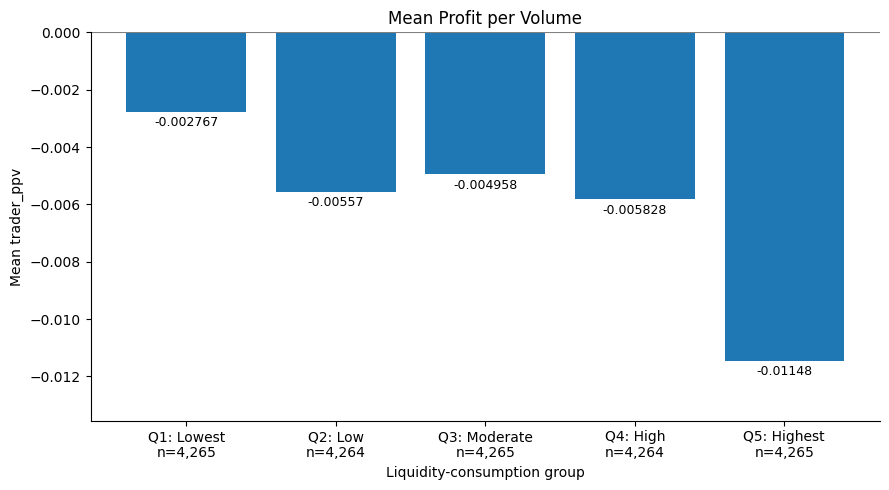

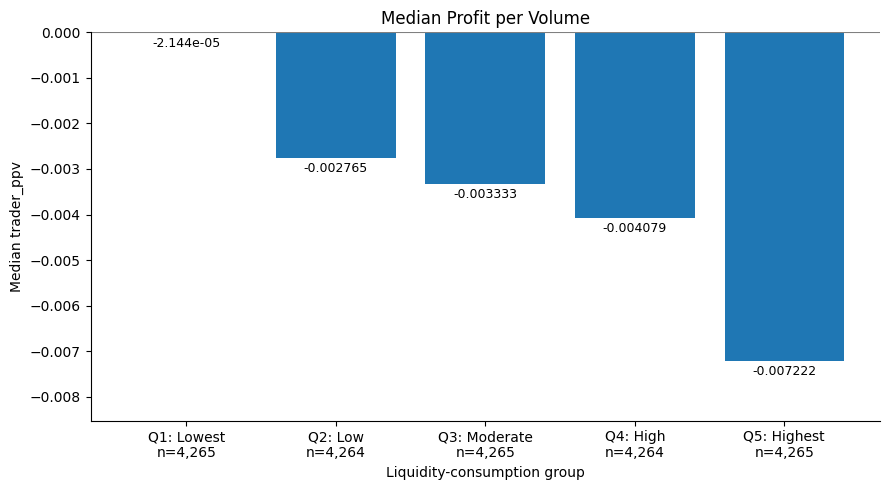

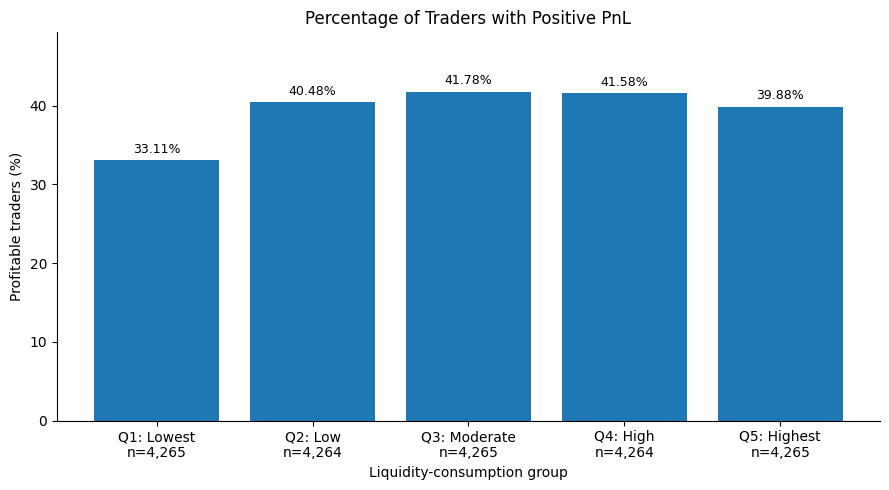

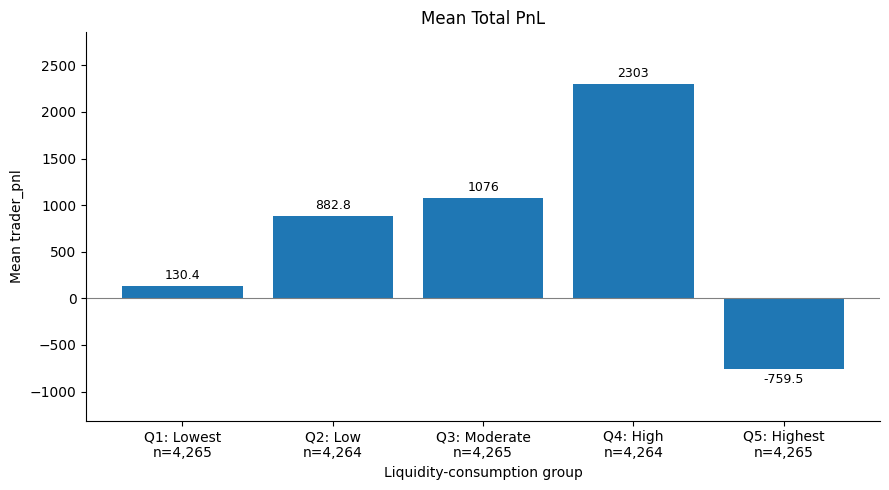

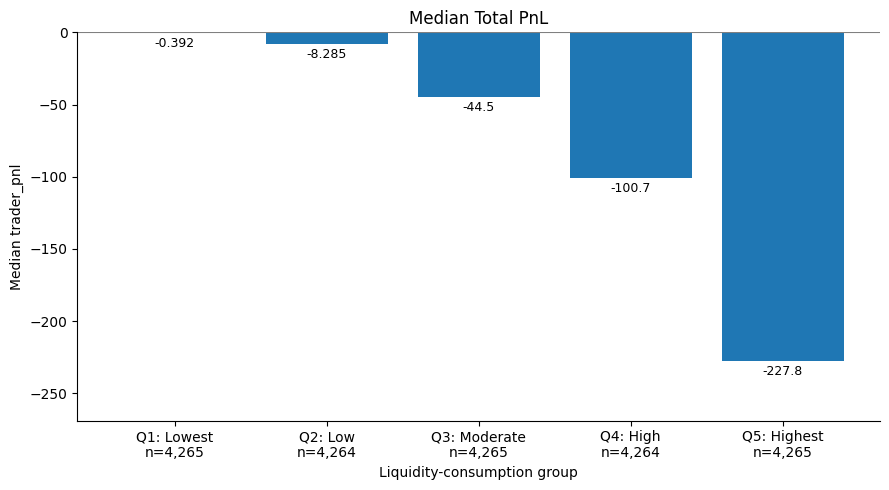

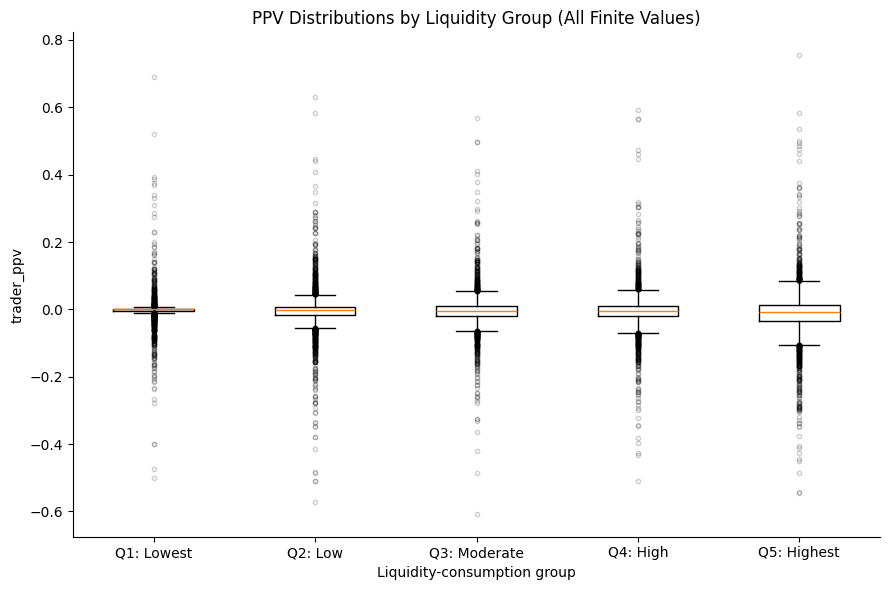

In [6]:
def group_summary(data):
    enriched=data.assign(profitable=data[PNL]>0,positive_profit=data[PNL].clip(lower=0),absolute_loss=-data[PNL].clip(upper=0))
    table=enriched.groupby('group',observed=False).agg(n=(PNL,'size'),n_profitable=('profitable','sum'),
        mean_pnl=(PNL,'mean'),median_pnl=(PNL,'median'),net_pnl=(PNL,'sum'),positive_profit=('positive_profit','sum'),
        absolute_losses=('absolute_loss','sum'),mean_ppv=(PPV,'mean'),median_ppv=(PPV,'median'),
        total_volume=('trader_volume','sum'),mean_volume=('trader_volume','mean'),
        mean_count=('transaction_count','mean'),median_count=('transaction_count','median'))
    table['profitable_percent']=100*table.n_profitable/table.n.replace(0,np.nan)
    table['trader_share_percent']=100*table.n/table.n.sum()
    table['positive_profit_share_percent']=100*table.positive_profit/table.positive_profit.sum() if table.positive_profit.sum()>0 else np.nan
    table['profitable_trader_share_percent']=100*table.n_profitable/table.n_profitable.sum() if table.n_profitable.sum()>0 else np.nan
    # Negative volume would invalidate economic share interpretation; keep records and flag.
    table['volume_share_percent']=100*table.total_volume/table.total_volume.sum() if data.trader_volume.ge(0).all() and table.total_volume.sum()>0 else np.nan
    return table
profitability=group_summary(main)
assert profitability.n.sum()==len(main)
assert np.allclose(profitability.net_pnl,profitability.positive_profit-profitability.absolute_losses)
with pd.option_context('display.max_columns',None): display(profitability)
def group_bar(values,title,ylabel,percent=False):
    fig,ax=plt.subplots(figsize=(9,5))
    bars=ax.bar(range(len(values)),values)
    ax.set_xticks(range(len(values)),[f'{group_names.get(g,g)}\nn={int(profitability.loc[g,"n"]):,}' for g in values.index])
    ax.axhline(0,color='gray',lw=.8)
    ax.set(title=title,xlabel='Liquidity-consumption group',ylabel=ylabel)
    ax.bar_label(bars,labels=[f'{v:.2f}%' if percent else f'{v:.4g}' for v in values],padding=3,fontsize=9)
    ax.margins(y=.18)
    fig.tight_layout(); plt.show(); plt.close(fig)
for col,title,ylabel in [('mean_ppv','Mean Profit per Volume','Mean trader_ppv'),('median_ppv','Median Profit per Volume','Median trader_ppv'),
                         ('profitable_percent','Percentage of Traders with Positive PnL','Profitable traders (%)'),
                         ('mean_pnl','Mean Total PnL','Mean trader_pnl'),('median_pnl','Median Total PnL','Median trader_pnl')]:
    group_bar(profitability[col],title,ylabel,percent=col=='profitable_percent')
fig,ax=plt.subplots(figsize=(9,6))
ax.boxplot([main.loc[main.group.eq(g),PPV] for g in groups],showfliers=True,flierprops={'markersize':3,'alpha':.2})
ax.set_xticks(range(1,len(groups)+1),[group_names[g] for g in groups])
ax.set(title='PPV Distributions by Liquidity Group (All Finite Values)',xlabel='Liquidity-consumption group',ylabel='trader_ppv')
fig.tight_layout(); plt.show(); plt.close(fig)

# 8. Aggregate Profit Shares
Compare positive-profit shares with shares of all traders, profitable traders, and total volume. Net PnL is shown separately and is not used as a positive-profit denominator. A large positive-profit share alone does not establish skill: capital, volume, and a few exceptional winners may explain it.

,n,trader_share_percent,positive_profit,positive_profit_share_percent,volume_share_percent,profitable_trader_share_percent,net_pnl
group,,,,,,,
Q1,4265,20.001876,1.685667e+06,2.391445,2.564795,16.821539,5.561750e+05
Q2,4264,19.997186,1.198766e+07,17.006824,17.299776,20.562306,3.764316e+06
Q3,4265,20.001876,1.817976e+07,25.791519,30.718243,21.229450,4.588698e+06
Q4,4264,19.997186,2.280997e+07,32.360365,32.077332,21.122230,9.818191e+06
Q5,4265,20.001876,1.582431e+07,22.449847,17.339854,20.264475,-3.239399e+06


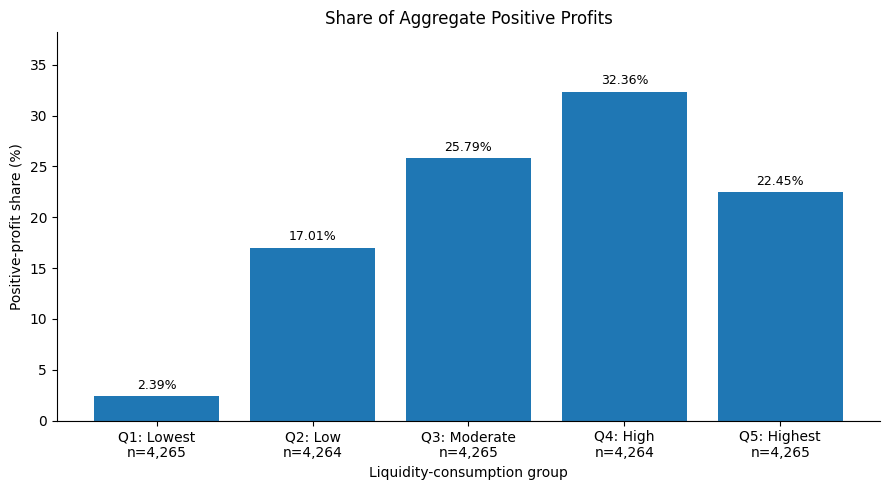

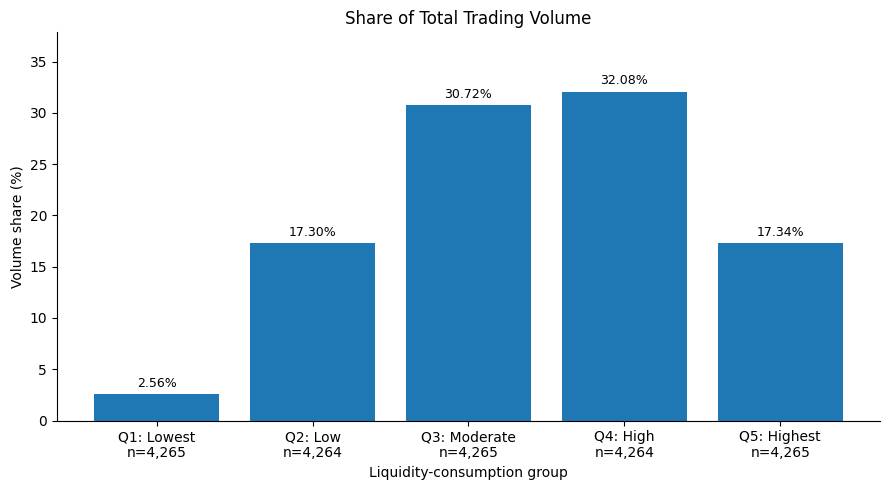

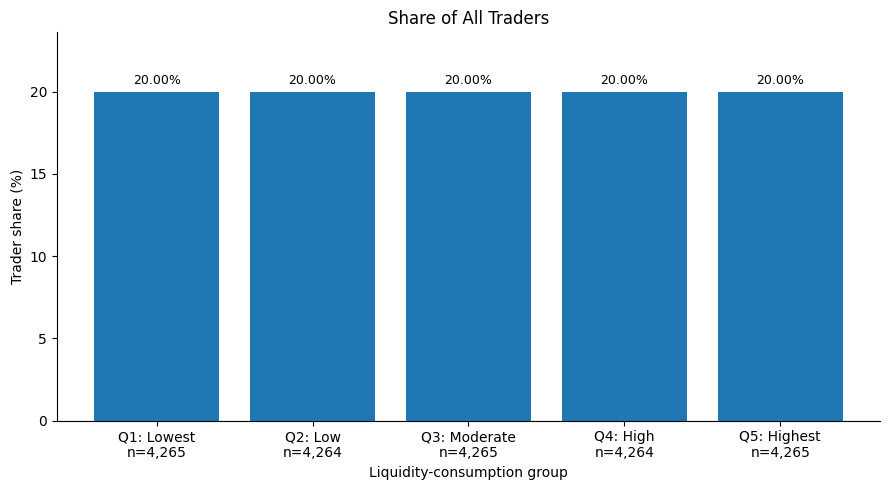

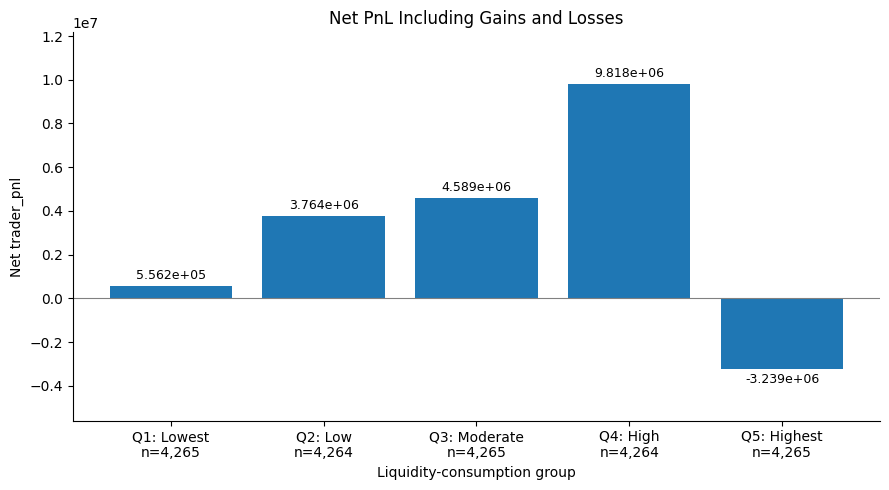

In [7]:
display(profitability[['n','trader_share_percent','positive_profit','positive_profit_share_percent','volume_share_percent','profitable_trader_share_percent','net_pnl']])
for col,title,ylabel in [('positive_profit_share_percent','Share of Aggregate Positive Profits','Positive-profit share (%)'),
                         ('volume_share_percent','Share of Total Trading Volume','Volume share (%)'),
                         ('trader_share_percent','Share of All Traders','Trader share (%)'),('net_pnl','Net PnL Including Gains and Losses','Net trader_pnl')]:
    group_bar(profitability[col],title,ylabel,percent=col!='net_pnl')

# 9. Within-Group Profit Concentration
Select positive-PnL traders **within the original full-sample groups**. Use the same ceiling convention as overall. Report selected counts and actual fractions. A target containing fewer than 10 traders is flagged as fragile; when n × target fraction < 1, the nominal percentile cannot be resolved even though the ceiling statistic is reported. These within-group shares differ from a group's share of all profits.

,group,n_profitable,target_top_percent,selected_n,actual_selected_percent,profit_share_percent,limitation
0,Q1,1412,1.0,15,1.062323,85.852001,
1,Q1,1412,5.0,71,5.028329,97.276740,
2,Q1,1412,10.0,142,10.056657,99.350059,
3,Q1,1412,20.0,283,20.042493,99.863270,
4,Q2,1726,1.0,18,1.042874,43.605459,
5,Q2,1726,5.0,87,5.040556,77.333796,
6,Q2,1726,10.0,173,10.023175,88.844503,
7,Q2,1726,20.0,346,20.046350,96.375271,
8,Q3,1782,1.0,18,1.010101,43.669390,
9,Q3,1782,5.0,90,5.050505,76.857976,


,n_profitable,positive_profit,gini
group,,,
Q1,1412,1.685667e+06,0.986557
Q2,1726,1.198766e+07,0.919530
Q3,1782,1.817976e+07,0.906830
Q4,1773,2.280997e+07,0.891483
Q5,1701,1.582431e+07,0.829951


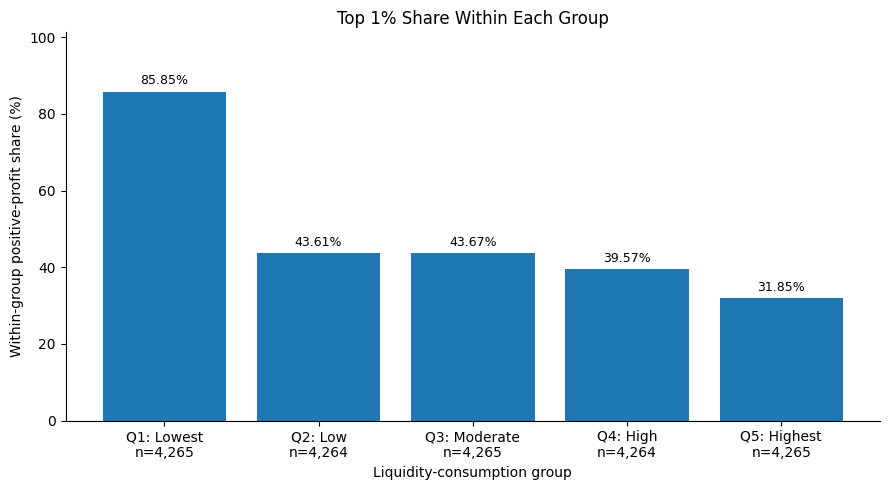

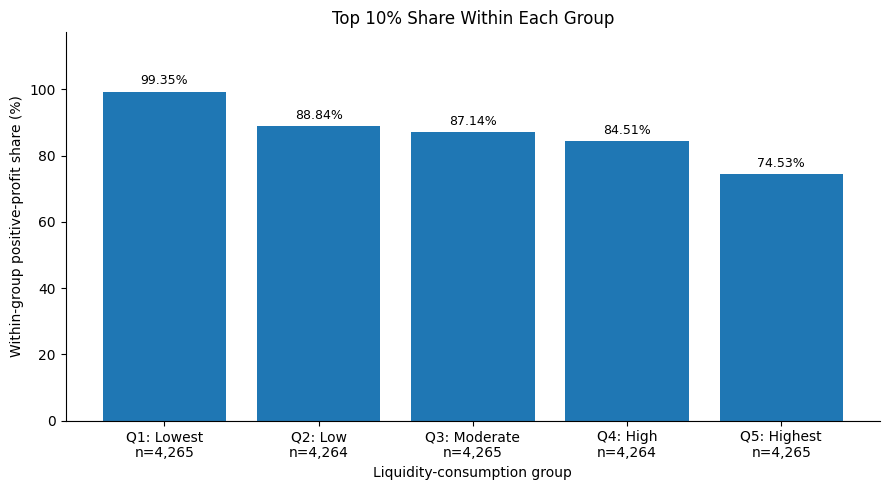

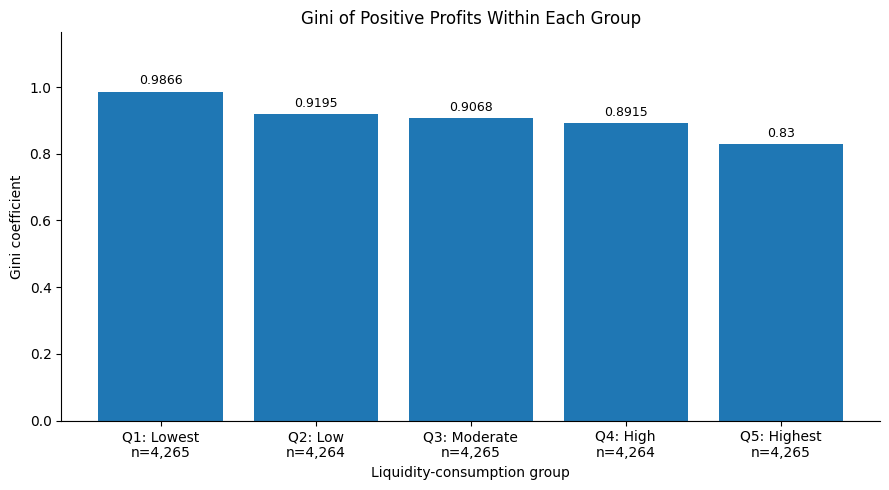

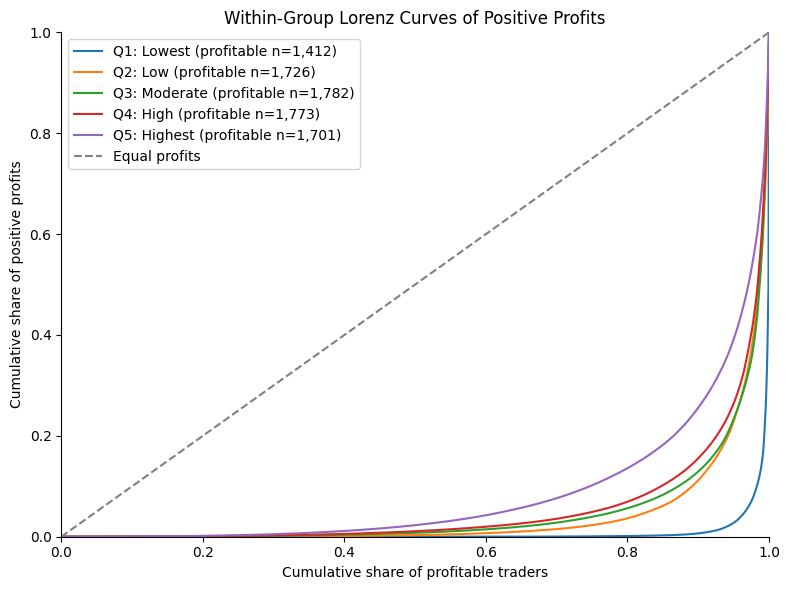

In [8]:
within_rows=[]; within_detail=[]
for g in groups:
    record=concentration(main.loc[main.group.eq(g),PNL],[.01,.05,.1,.2])
    within_rows.append(dict(group=g,**record))
    for f in [.01,.05,.1,.2]:
        n,k=record['n_profitable'],record[f'top_{f:g}_n']
        within_detail.append({'group':g,'n_profitable':n,'target_top_percent':100*f,'selected_n':k,
            'actual_selected_percent':100*k/n if n else np.nan,'profit_share_percent':100*record[f'top_{f:g}_share'],
            'limitation':'No profitable traders' if n==0 else ('Nominal percentile below one trader' if n*f<1 else ('Fewer than 10 selected traders' if k<10 else ''))})
within=pd.DataFrame(within_rows).set_index('group')
display(pd.DataFrame(within_detail)); display(within[['n_profitable','positive_profit','gini']])
group_bar(100*within['top_0.01_share'],'Top 1% Share Within Each Group','Within-group positive-profit share (%)',True)
group_bar(100*within['top_0.1_share'],'Top 10% Share Within Each Group','Within-group positive-profit share (%)',True)
group_bar(within.gini,'Gini of Positive Profits Within Each Group','Gini coefficient')
fig,ax=plt.subplots(figsize=(8,6))
for g in groups:
    curve=lorenz(main.loc[main.group.eq(g),PNL])
    if curve is not None: ax.plot(*curve,label=f'{group_names[g]} (profitable n={int(within.loc[g,"n_profitable"]):,})')
ax.plot([0,1],[0,1],'--',color='gray',label='Equal profits')
ax.set(xlim=(0,1),ylim=(0,1),title='Within-Group Lorenz Curves of Positive Profits',xlabel='Cumulative share of profitable traders',ylabel='Cumulative share of positive profits')
ax.legend(); fig.tight_layout(); plt.show(); plt.close(fig)

# 10. Statistical Significance
Use Pearson and Spearman correlations, Welch's ANOVA for unequal-variance group means, and a chi-square test of profitable/nonprofitable proportions. Report a prespecified lowest-minus-highest mean PPV contrast with Welch confidence interval and a corresponding profitable-rate difference in percentage points. These estimate practical differences rather than relying on significance alone. The highest and lowest groups are chosen by liquidity, not by observed profits.

BH correction covers the correlation tests, omnibus tests, and planned mean/proportion comparisons shown here. All assume independent traders. The bootstrap in Section 11 separately reports the prespecified lowest-minus-highest **median PPV** difference; no claim is based on interpreting Kruskal–Wallis as a median test.

In [9]:
test_rows=[]
for outcome in [PPV,PNL]:
    for method,fn in [('Pearson',stats.pearsonr),('Spearman',stats.spearmanr)]:
        r,p=fn(main[L],main[outcome]) if main[L].nunique()>1 and main[outcome].nunique()>1 else (np.nan,np.nan)
        test_rows.append({'test':f'{method}: liquidity vs {outcome}','effect':r,'effect_units':'correlation','statistic':r,'p_value':p,'n':len(main)})
arrays=[main.loc[main.group.eq(g),PPV].to_numpy() for g in groups]
mean_contrast=None; proportion_contrast=None
if len(groups)>1 and all(len(a)>1 and np.var(a)>0 for a in arrays):
    welch=anova_oneway(arrays,use_var='unequal',welch_correction=True)
    test_rows.append({'test':'Welch ANOVA: mean PPV','effect':float(profitability.mean_ppv.max()-profitability.mean_ppv.min()),
                     'effect_units':'largest minus smallest group mean PPV (descriptive)','statistic':float(welch.statistic),'p_value':float(welch.pvalue),'n':len(main)})
    print('Welch ANOVA numerator/denominator degrees of freedom:',welch.df)
    a,b=arrays[0],arrays[-1]
    va,vb=np.var(a,ddof=1)/len(a),np.var(b,ddof=1)/len(b)
    se=np.sqrt(va+vb); dof=(va+vb)**2/(va**2/(len(a)-1)+vb**2/(len(b)-1))
    difference=a.mean()-b.mean(); critical=stats.t.ppf(.975,dof)
    mean_contrast={'comparison':f'{low} minus {high}','difference':difference,'ci95_low':difference-critical*se,'ci95_high':difference+critical*se,'n_low':len(a),'n_high':len(b)}
    test_rows.append({'test':'Planned low-high mean PPV','effect':difference,'effect_units':'PPV','statistic':difference/se,'p_value':2*stats.t.sf(abs(difference/se),dof),'n':len(a)+len(b)})
    display(pd.DataFrame([mean_contrast]))
else:
    print('Mean comparisons require multiple groups with adequate variation.')
contingency=np.column_stack([profitability.n_profitable,profitability.n-profitability.n_profitable])
if len(groups)>1 and (contingency.sum(axis=0)>0).all() and (contingency.sum(axis=1)>0).all():
    chi,p,dof,expected=stats.chi2_contingency(contingency,correction=False)
    print('Minimum expected proportion-test cell count:',expected.min())
    test_rows.append({'test':'Chi-square: profitable rates','effect':float(np.sqrt(chi/len(main))), 'effect_units':"Cramer's V (0 = no association)", 'statistic':chi,'p_value':p if expected.min()>=5 else np.nan,'n':len(main)})
    if expected.min()<5: print('Sparse expected cells: asymptotic p-value withheld.')
    pa,pb=profitability.loc[low,'n_profitable']/profitability.loc[low,'n'],profitability.loc[high,'n_profitable']/profitability.loc[high,'n']
    na,nb=profitability.loc[low,'n'],profitability.loc[high,'n']
    se=np.sqrt(pa*(1-pa)/na+pb*(1-pb)/nb)
    # Large-sample unpooled interval; pooled null variance for the z test.
    pooled=(profitability.loc[low,'n_profitable']+profitability.loc[high,'n_profitable'])/(na+nb)
    null_se=np.sqrt(pooled*(1-pooled)*(1/na+1/nb))
    p=2*stats.norm.sf(abs((pa-pb)/null_se)) if null_se>0 else np.nan
    proportion_contrast={'comparison':f'{low} minus {high}','difference_pp':100*(pa-pb),'ci95_low_pp':100*(pa-pb-1.96*se),'ci95_high_pp':100*(pa-pb+1.96*se)}
    display(pd.DataFrame([proportion_contrast]))
    test_rows.append({'test':'Planned low-high profitable rate','effect':100*(pa-pb),'effect_units':'percentage points','statistic':(pa-pb)/null_se if null_se>0 else np.nan,'p_value':p,'n':na+nb})
tests=pd.DataFrame(test_rows)
tests['q_bh']=np.nan
valid=tests.p_value.notna()
if valid.any(): tests.loc[valid,'q_bh']=multipletests(tests.loc[valid,'p_value'],method='fdr_bh')[1]
with pd.option_context('display.max_columns',None): display(tests)

Welch ANOVA numerator/denominator degrees of freedom: (4.0, np.float64(10524.30910828544))
Minimum expected proportion-test cell count: 1678.5638043427284


,comparison,difference,ci95_low,ci95_high,n_low,n_high
0,Q1 minus Q5,0.008708,0.006327,0.01109,4265,4265


,comparison,difference_pp,ci95_low_pp,ci95_high_pp
0,Q1 minus Q5,-6.776084,-8.814315,-4.737854


,test,effect,effect_units,statistic,p_value,n,q_bh
0,Pearson: liquidity vs trader_ppv,-0.071657,correlation,-0.071657,1.107516e-25,21323,2.953377e-25
1,Spearman: liquidity vs trader_ppv,-0.072323,correlation,-0.072323,3.927054e-26,21323,1.570822e-25
2,Pearson: liquidity vs trader_pnl,-0.035366,correlation,-0.035366,2.396225e-07,21323,2.396225e-07
3,Spearman: liquidity vs trader_pnl,-0.135509,correlation,-0.135509,6.296624e-88,21323,5.037299e-87
4,Welch ANOVA: mean PPV,0.008708,largest minus smallest group mean PPV (descrip...,13.373762,7.148626e-11,21323,9.188545e-11
5,Planned low-high mean PPV,0.008708,PPV,7.168277,8.450080e-13,8530,1.352013e-12
6,Chi-square: profitable rates,0.065645,Cramer's V (0 = no association),91.885159,5.235500e-19,21323,1.047100e-18
7,Planned low-high profitable rate,-6.776084,percentage points,-6.499851,8.039977e-11,8530,9.188545e-11


# 11. Bootstrap Confidence Intervals
Use 1,000 replications and seed 20260920. Independently resample **all trader records within each original liquidity group**, with replacement and fixed original group size; keep paired PnL/PPV values from each sampled trader. Group boundaries are not re-estimated. Then select positive-PnL traders within each replicate to compute top shares and Gini. Thus the number of profitable traders can vary. This is a stratified bootstrap conditional on group membership and group sizes.

Replicates with no profitable traders return missing concentration estimates, not zero. Report valid replication counts; with fewer than 95% valid draws withhold the interval. Percentile intervals describe sampling uncertainty under independent-trader assumptions; heavy tails and a few exceptional winners can make them unstable. The empirical bootstrap cannot represent unseen extreme winners.

Also calculate low-minus-high concentration differences from paired bootstrap iterations. The **median PPV difference** uses all sampled traders and addresses typical profitability, not concentration. These are prespecified, pointwise 95% intervals, not simultaneous intervals across all metrics.

In [10]:
BOOTSTRAPS=1000
rng=np.random.default_rng(20260920)
metric_names=['top_0.01_share','top_0.1_share','gini']
boot={}; boot_medians={}
for g in groups:
    records=main.loc[main.group.eq(g),[PNL,PPV]].to_numpy()
    estimates=np.full((BOOTSTRAPS,3),np.nan); medians=np.full(BOOTSTRAPS,np.nan)
    for iteration in range(BOOTSTRAPS):
        draw=records[rng.integers(0,len(records),size=len(records))]
        result=concentration(draw[:,0])
        estimates[iteration]=[result[m] for m in metric_names]
        medians[iteration]=np.median(draw[:,1])
    boot[g]=estimates; boot_medians[g]=medians
    print(f'Completed {BOOTSTRAPS:,} trader bootstrap draws for {g}.')
def bootstrap_interval(draws):
    finite=np.asarray(draws)[np.isfinite(draws)]; n=len(finite)
    interval=np.quantile(finite,[.025,.975]) if n>=.95*BOOTSTRAPS else [np.nan,np.nan]
    return {'ci95_low':interval[0],'ci95_high':interval[1],'valid_draws':n,'total_draws':BOOTSTRAPS}
bootstrap_rows=[]
for g in groups:
    for j,m in enumerate(metric_names):
        bootstrap_rows.append(dict(group=g,metric=m,estimate=within.loc[g,m],**bootstrap_interval(boot[g][:,j])))
bootstrap_results=pd.DataFrame(bootstrap_rows)
display(bootstrap_results)
bootstrap_differences=pd.DataFrame()
median_contrast=None
if low!=high:
    bootstrap_differences=pd.DataFrame([dict(metric=m,comparison=f'{low} minus {high}',estimate=within.loc[low,m]-within.loc[high,m],**bootstrap_interval(boot[low][:,j]-boot[high][:,j])) for j,m in enumerate(metric_names)])
    display(bootstrap_differences)
    median_contrast=dict(comparison=f'{low} minus {high}',estimate=profitability.loc[low,'median_ppv']-profitability.loc[high,'median_ppv'],**bootstrap_interval(boot_medians[low]-boot_medians[high]))
    print('Median PPV difference (all traders, separate from concentration uncertainty):')
    display(pd.DataFrame([median_contrast]))

Completed 1,000 trader bootstrap draws for Q1.
Completed 1,000 trader bootstrap draws for Q2.
Completed 1,000 trader bootstrap draws for Q3.
Completed 1,000 trader bootstrap draws for Q4.
Completed 1,000 trader bootstrap draws for Q5.
Median PPV difference (all traders, separate from concentration uncertainty):


,group,metric,estimate,ci95_low,ci95_high,valid_draws,total_draws
0,Q1,top_0.01_share,0.858520,0.638832,0.929551,1000,1000
1,Q1,top_0.1_share,0.993501,0.980612,0.997143,1000,1000
2,Q1,gini,0.986557,0.968496,0.991780,1000,1000
3,Q2,top_0.01_share,0.436055,0.342890,0.502293,1000,1000
4,Q2,top_0.1_share,0.888445,0.858255,0.909575,1000,1000
5,Q2,gini,0.919530,0.903784,0.930625,1000,1000
6,Q3,top_0.01_share,0.436694,0.380146,0.486483,1000,1000
7,Q3,top_0.1_share,0.871391,0.840777,0.894440,1000,1000
8,Q3,gini,0.906830,0.890526,0.918227,1000,1000
9,Q4,top_0.01_share,0.395749,0.335878,0.448942,1000,1000


,metric,comparison,estimate,ci95_low,ci95_high,valid_draws,total_draws
0,top_0.01_share,Q1 minus Q5,0.540051,0.313178,0.639054,1000,1000
1,top_0.1_share,Q1 minus Q5,0.248223,0.213140,0.287741,1000,1000
2,gini,Q1 minus Q5,0.156605,0.128049,0.179676,1000,1000


,comparison,estimate,ci95_low,ci95_high,valid_draws,total_draws
0,Q1 minus Q5,0.007201,0.006163,0.008687,1000,1000


# 12. Controlled Regression
Fit OLS for raw PPV with raw liquidity plus centered log1p transaction size, frequency, and markets per day. For unexpected negative controls, retain values and use signed log1p(abs(x)) with a warning. Control coefficients are per transformed unit; PPV is not logged. Compare unadjusted and adjusted models on identical control-complete samples, as well as the primary unadjusted sample.

Use HC3 heteroskedasticity-robust standard errors and normal-reference inference. HC3 does not remove outlier influence or account for shared-market dependence. Report correlations and VIFs; VIF > 10 is a warning, not an automatic variable deletion rule. A separate volume-adjusted sensitivity model recognizes that volume may form PPV's denominator and may share construction with other controls.

In [11]:
def transformed(data,columns):
    result=data.copy(); names=[]
    for col in columns:
        x=result[col]
        if x.lt(0).any(): print(f'Negative {col}: signed log1p used; investigate definition.')
        z=np.sign(x)*np.log1p(np.abs(x)); name='log_'+col+'_c'
        result[name]=z-z.mean(); names.append(name)
        print(f'{col}: raw skew={x.skew():.3g}, transformed skew={z.skew():.3g}')
    return result,names
def regression(data,extra=()):
    model=smf.ols(f'{PPV} ~ {L}'+(' + '+' + '.join(extra) if extra else ''),data=data,missing='raise').fit(cov_type='HC3',use_t=False)
    if np.linalg.matrix_rank(model.model.exog)<model.model.exog.shape[1]: raise ValueError('Rank-deficient model.')
    return model
def coef_table(model):
    ci=model.conf_int()
    return pd.DataFrame({'coefficient':model.params,'HC3_SE':model.bse,'ci95_low':ci[0],'ci95_high':ci[1],'p_two_sided':model.pvalues,'n':int(model.nobs),'R_squared':model.rsquared})
reg_sample=sample_for([L,PPV]+controls,label='Controlled regression')
reg_sample,names=transformed(reg_sample,controls)
unadjusted=regression(main); matched=regression(reg_sample); adjusted=regression(reg_sample,names)
regression_rows=[]
for label,model in [('Unadjusted main sample',unadjusted),('Unadjusted control-complete sample',matched),('Controlled',adjusted)]:
    print(label); display(coef_table(model))
    record=coef_table(model).loc[L].to_dict(); record['model']=label; regression_rows.append(record)
regression_comparison=pd.DataFrame(regression_rows)
display(regression_comparison)
print('Transformed predictor correlations:'); display(reg_sample[[L]+names].corr())
def vif_report(data,names):
    x=data[[L]+names]; sd=x.std(ddof=0)
    if sd.eq(0).any(): print('Constant predictors prevent VIF calculation.'); return
    design=sm.add_constant((x-x.mean())/sd)
    table=pd.DataFrame({'predictor':design.columns[1:],'VIF':[variance_inflation_factor(design.to_numpy(),i) for i in range(1,design.shape[1])]})
    display(table); print('VIF > 10:',table.loc[table.VIF>10,'predictor'].tolist())
vif_report(reg_sample,names)
volume_sample=sample_for([L,PPV,'trader_volume']+controls,label='Volume-adjusted sensitivity')
volume_sample,volume_names=transformed(volume_sample,controls+['trader_volume'])
volume_model=regression(volume_sample,volume_names)
display(coef_table(volume_model)); vif_report(volume_sample,volume_names)
print('Trading activity across main liquidity groups:')
display(profitability[['n','mean_volume','total_volume','mean_count','median_count']])
pnl=working.loc[volume_sample.index,PNL]
valid=volume_sample.trader_volume.gt(0)&np.isfinite(pnl)
if valid.any():
    ratio=pnl.loc[valid]/volume_sample.loc[valid,'trader_volume']
    print(f'PPV matches PNL/volume (n={valid.sum():,}, rtol=1e-5, atol=1e-8): {np.isclose(volume_sample.loc[valid,PPV],ratio,rtol=1e-5,atol=1e-8).mean():.2%}')

mean_tx_value: raw skew=9.59, transformed skew=-0.167
transactions_per_day: raw skew=24.8, transformed skew=1
markets_per_day: raw skew=5.29, transformed skew=0.911
Unadjusted main sample
Unadjusted control-complete sample
Controlled
Transformed predictor correlations:
VIF > 10: []
mean_tx_value: raw skew=9.59, transformed skew=-0.167
transactions_per_day: raw skew=24.8, transformed skew=1
markets_per_day: raw skew=5.29, transformed skew=0.911
trader_volume: raw skew=22.4, transformed skew=0.0863
VIF > 10: []
Trading activity across main liquidity groups:
PPV matches PNL/volume (n=21,323, rtol=1e-5, atol=1e-8): 100.00%


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Controlled regression,100,524760,21323,0,21323


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared
Intercept,-0.004076,0.000520,-0.005095,-0.003058,4.324973e-15,21323,0.005135
price_levels_per_transaction,-0.253717,0.057738,-0.366881,-0.140552,1.111465e-05,21323,0.005135


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared
Intercept,-0.004076,0.000520,-0.005095,-0.003058,4.324973e-15,21323,0.005135
price_levels_per_transaction,-0.253717,0.057738,-0.366881,-0.140552,1.111465e-05,21323,0.005135


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared
Intercept,-0.003746,0.000562,-0.004847,-0.002645,2.594216e-11,21323,0.007756
price_levels_per_transaction,-0.294706,0.061042,-0.414347,-0.175065,1.379876e-06,21323,0.007756
log_mean_tx_value_c,0.001138,0.000327,0.000498,0.001779,4.976578e-04,21323,0.007756
log_transactions_per_day_c,0.000445,0.000421,-0.000381,0.001270,2.909159e-01,21323,0.007756
log_markets_per_day_c,-0.003256,0.000795,-0.004815,-0.001698,4.197464e-05,21323,0.007756


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared,model
0,-0.253717,0.057738,-0.366881,-0.140552,0.000011,21323.0,0.005135,Unadjusted main sample
1,-0.253717,0.057738,-0.366881,-0.140552,0.000011,21323.0,0.005135,Unadjusted control-complete sample
2,-0.294706,0.061042,-0.414347,-0.175065,0.000001,21323.0,0.007756,Controlled


... (2 outputs left out)

,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Volume-adjusted sensitivity,100,524760,21323,0,21323


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared
Intercept,-0.003684,0.000563,-0.004787,-0.002582,5.801385e-11,21323,0.008554
price_levels_per_transaction,-0.302394,0.061722,-0.423367,-0.181422,9.616729e-07,21323,0.008554
log_mean_tx_value_c,-0.000378,0.000468,-0.001296,0.000539,4.188349e-01,21323,0.008554
log_transactions_per_day_c,-0.000050,0.000443,-0.000919,0.000819,9.102012e-01,21323,0.008554
log_markets_per_day_c,-0.003354,0.000793,-0.004907,-0.001800,2.327056e-05,21323,0.008554
log_trader_volume_c,0.001370,0.000269,0.000844,0.001897,3.375776e-07,21323,0.008554


,predictor,VIF
0,price_levels_per_transaction,1.094126
1,log_mean_tx_value_c,3.625419
2,log_transactions_per_day_c,1.333327
3,log_markets_per_day_c,1.289583
4,log_trader_volume_c,3.598382


,n,mean_volume,total_volume,mean_count,median_count
group,,,,,
Q1,4265,33498.800735,1.428724e+08,384.827902,151.0
Q2,4264,226005.483328,9.636874e+08,925.760553,164.0
Q3,4265,401211.189377,1.711166e+09,1259.212896,233.0
Q4,4264,419060.509333,1.786874e+09,1234.864681,274.0
Q5,4265,226475.953517,9.659199e+08,663.550293,224.0


# 13. Robustness Checks
Repeat key group profitability and concentration calculations at thresholds 50, 100, and 500. Threshold sensitivity re-estimates quintile boundaries on each threshold sample, with boundaries reported explicitly; the main bootstrap and all main analyses retain the original boundaries. Re-estimated threshold groups compare relative consumption ranks, not identical absolute ranges. Changing thresholds cannot recover traders removed during earlier cleaning of `data_no_imputation.parquet`.

For exceptional-profit sensitivity, exclude the top 0.1% and 1% **of positive-PnL traders** using ceiling counts, including all traders tied at the cutoff. Report the actual number excluded. Keep original liquidity-group assignments and recompute denominators on retained traders. Negative and zero-PnL traders remain. These exclusions are prespecified sensitivities, not the primary result or a search for significance.

Mean and median PPV, mean and median PnL, net PnL, and positive-profit concentration answer different questions and are reported together. Alternative weighted/volume-normalized liquidity measures are not modeled because available project documentation does not verify their definitions and units. Do not infer maker/taker status or slippage from their names.

In [12]:
sensitivity_rows=[]; sensitivity_group_tables=[]
def sensitivity_summary(data,label):
    table=group_summary(data)
    concentration_rows=[]
    for g in data.group.cat.categories:
        record=concentration(data.loc[data.group.eq(g),PNL],[.01,.05,.1,.2])
        concentration_rows.append(dict(group=g,**record))
    conc=pd.DataFrame(concentration_rows).set_index('group')
    details=table.join(conc[['gini','top_0.01_share','top_0.05_share','top_0.1_share','top_0.2_share']])
    details['analysis']=label
    sensitivity_group_tables.append(details.reset_index())
    global_conc=concentration(data[PNL])
    first,last=data.group.cat.categories[0],data.group.cat.categories[-1]
    row={'analysis':label,'n':len(data),'n_profitable':global_conc['n_profitable'],'net_pnl':data[PNL].sum(),
         'positive_profit':global_conc['positive_profit'],'overall_gini':global_conc['gini'],'overall_top1_share':global_conc['top_0.01_share'],
         'overall_top10_share':global_conc['top_0.1_share'],'lowest_profit_share_percent':table.loc[first,'positive_profit_share_percent'],
         'lowest_trader_share_percent':table.loc[first,'trader_share_percent'],'lowest_volume_share_percent':table.loc[first,'volume_share_percent'],
         'low_minus_high_mean_ppv':table.loc[first,'mean_ppv']-table.loc[last,'mean_ppv'],
         'low_minus_high_median_ppv':table.loc[first,'median_ppv']-table.loc[last,'median_ppv'],
         'low_minus_high_top1_share':conc.loc[first,'top_0.01_share']-conc.loc[last,'top_0.01_share']}
    sensitivity_rows.append(row)
    print(label)
    with pd.option_context('display.max_columns',None): display(details)

sensitivity_summary(main,'Threshold 100 (primary)')
for threshold in [50,500]:
    data=sample_for(core,threshold,label=f'Threshold {threshold}')
    data,edges,ranges=make_groups(data,f'Threshold {threshold} re-estimated quintiles')
    sensitivity_summary(data,f'Threshold {threshold}')
exclusion_rows=[]
positive=main.loc[main[PNL]>0,PNL].sort_values(ascending=False)
for fraction in [.001,.01]:
    if positive.empty:
        print('Top-profit sensitivity skipped: no profitable traders.'); continue
    target=min(len(positive),max(1,int(np.ceil(fraction*len(positive)))))
    cutoff=positive.iloc[target-1]
    excluded=main[PNL].ge(cutoff)&main[PNL].gt(0)
    retained=main.loc[~excluded].copy()
    label=f'Exclude top {100*fraction:g}% positive-PnL traders (ties included)'
    exclusion_rows.append({'analysis':label,'target_excluded_n':target,'actual_excluded_n':int(excluded.sum()),
                           'cutoff_pnl':cutoff,'actual_percent_profitable_excluded':100*excluded.sum()/len(positive),'retained_n':len(retained)})
    sensitivity_summary(retained,label)
display(pd.DataFrame(exclusion_rows))
sensitivity=pd.DataFrame(sensitivity_rows)
with pd.option_context('display.max_columns',None): display(sensitivity)
all_sensitivity_groups=pd.concat(sensitivity_group_tables,ignore_index=True)
alternatives=[c for c in ['price_levels_consumed_vw','price_levels_vw_per_transaction','price_levels_per_volume'] if c in working]
display(pd.DataFrame({'alternative_measure':alternatives,'decision':['Not fitted: weighting/normalization units unverified']*len(alternatives)}))
print('Sample audits:'); display(pd.DataFrame(audits))

Threshold 100 (primary)
Threshold 50 re-estimated quintiles: 5 groups.
Threshold 50
Threshold 500 re-estimated quintiles: 5 groups.
Threshold 500
Exclude top 0.1% positive-PnL traders (ties included)
Exclude top 1% positive-PnL traders (ties included)
Sample audits:


,n,n_profitable,mean_pnl,median_pnl,net_pnl,positive_profit,absolute_losses,mean_ppv,median_ppv,total_volume,mean_volume,mean_count,median_count,profitable_percent,trader_share_percent,positive_profit_share_percent,profitable_trader_share_percent,volume_share_percent,gini,top_0.01_share,top_0.05_share,top_0.1_share,top_0.2_share,analysis
group,,,,,,,,,,,,,,,,,,,,,,,,
Q1,4265,1412,130.404455,-0.391980,5.561750e+05,1.685667e+06,1.129492e+06,-0.002767,-0.000021,1.428724e+08,33498.800735,384.827902,151.0,33.106682,20.001876,2.391445,16.821539,2.564795,0.986557,0.858520,0.972767,0.993501,0.998633,Threshold 100 (primary)
Q2,4264,1726,882.813415,-8.285433,3.764316e+06,1.198766e+07,8.223347e+06,-0.005570,-0.002765,9.636874e+08,226005.483328,925.760553,164.0,40.478424,19.997186,17.006824,20.562306,17.299776,0.919530,0.436055,0.773338,0.888445,0.963753,Threshold 100 (primary)
Q3,4265,1782,1075.896412,-44.502901,4.588698e+06,1.817976e+07,1.359107e+07,-0.004958,-0.003333,1.711166e+09,401211.189377,1259.212896,233.0,41.781946,20.001876,25.791519,21.229450,30.718243,0.906830,0.436694,0.768580,0.871391,0.943626,Threshold 100 (primary)
Q4,4264,1773,2302.577592,-100.699593,9.818191e+06,2.280997e+07,1.299178e+07,-0.005828,-0.004079,1.786874e+09,419060.509333,1234.864681,274.0,41.580675,19.997186,32.360365,21.122230,32.077332,0.891483,0.395749,0.736587,0.845051,0.930749,Threshold 100 (primary)
Q5,4265,1701,-759.530857,-227.799334,-3.239399e+06,1.582431e+07,1.906371e+07,-0.011475,-0.007222,9.659199e+08,226475.953517,663.550293,224.0,39.882767,20.001876,22.449847,20.264475,17.339854,0.829951,0.318469,0.611082,0.745277,0.864524,Threshold 100 (primary)


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Threshold 50,50,524760,50567,0,50567


,observed_min,observed_max,n,lower_boundary,upper_boundary
group,,,,,
Q1,0.000000,0.000013,10114,0.000000,0.000013
Q2,0.000013,0.000912,10113,0.000013,0.000912
Q3,0.000912,0.002939,10113,0.000912,0.002940
Q4,0.002940,0.008125,10114,0.002940,0.008125
Q5,0.008125,0.771136,10113,0.008125,0.771136


,n,n_profitable,mean_pnl,median_pnl,net_pnl,positive_profit,absolute_losses,mean_ppv,median_ppv,total_volume,mean_volume,mean_count,median_count,profitable_percent,trader_share_percent,positive_profit_share_percent,profitable_trader_share_percent,volume_share_percent,gini,top_0.01_share,top_0.05_share,top_0.1_share,top_0.2_share,analysis
group,,,,,,,,,,,,,,,,,,,,,,,,
Q1,10114,3186,-14.892693,-0.278065,-1.506247e+05,3.556407e+05,5.062654e+05,-0.003149,-0.000037,9.113667e+07,9010.942520,129.500395,73.0,31.500890,20.001187,0.462147,17.076700,1.542080,0.974792,0.749614,0.942298,0.978169,0.993563,Threshold 50
Q2,10113,3732,198.655649,-1.615512,2.009005e+06,6.939215e+06,4.930210e+06,-0.004138,-0.001304,3.875115e+08,38318.153953,233.738554,80.0,36.902996,19.999209,9.017359,20.003216,6.556897,0.972506,0.760065,0.934645,0.972530,0.991193,Threshold 50
Q3,10113,3891,129.502062,-2.685528,1.309654e+06,1.170892e+07,1.039926e+07,-0.005880,-0.002179,1.174604e+09,116147.962493,461.608227,85.0,38.475230,19.999209,15.215481,20.855443,19.874920,0.939415,0.502618,0.835042,0.929638,0.976470,Threshold 50
Q4,10114,3947,895.151709,-24.540821,9.053564e+06,2.889672e+07,1.984315e+07,-0.007917,-0.004337,2.557081e+09,252825.918710,762.700316,118.0,39.025114,20.001187,37.550654,21.155598,43.267154,0.923560,0.526996,0.810899,0.896628,0.956384,Threshold 50
Q5,10113,3901,-0.312308,-135.310702,-3.158367e+03,2.905347e+07,2.905663e+07,-0.013992,-0.008744,1.699649e+09,168065.753489,498.534362,124.0,38.574113,19.999209,37.754359,20.909042,28.758949,0.870314,0.396177,0.690883,0.809257,0.905333,Threshold 50


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Threshold 500,500,524760,4679,0,4679


... (4 outputs left out)

,analysis,target_excluded_n,actual_excluded_n,cutoff_pnl,actual_percent_profitable_excluded,retained_n
0,Exclude top 0.1% positive-PnL traders (ties in...,9,9,646554.507436,0.107219,21314
1,Exclude top 1% positive-PnL traders (ties incl...,84,84,176056.214961,1.000715,21239


,analysis,n,n_profitable,net_pnl,positive_profit,overall_gini,overall_top1_share,overall_top10_share,lowest_profit_share_percent,lowest_trader_share_percent,lowest_volume_share_percent,low_minus_high_mean_ppv,low_minus_high_median_ppv,low_minus_high_top1_share
0,Threshold 100 (primary),21323,8394,1.548798e+07,7.048737e+07,0.907323,0.439751,0.863286,2.391445,20.001876,2.564795,0.008708,0.007201,0.540051
1,Threshold 50,50567,18657,1.221844e+07,7.695396e+07,0.938945,0.554269,0.917311,0.462147,20.001187,1.542080,0.010843,0.008707,0.353437
2,Threshold 500,4679,2235,2.027550e+07,5.195810e+07,0.839889,0.255332,0.758778,13.848756,20.004274,13.121407,0.002473,0.002381,0.109858
3,Exclude top 0.1% positive-PnL traders (ties in...,21314,8385,8.604690e+06,6.360408e+07,0.899436,0.403009,0.849956,1.328359,20.005630,2.656826,0.008586,0.007201,0.411472
4,Exclude top 1% positive-PnL traders (ties incl...,21239,8310,-1.550889e+07,3.949050e+07,0.859014,0.252872,0.776835,2.139478,20.076275,3.182245,0.009086,0.007368,0.543888


,alternative_measure,decision
0,price_levels_consumed_vw,Not fitted: weighting/normalization units unve...
1,price_levels_vw_per_transaction,Not fitted: weighting/normalization units unve...
2,price_levels_per_volume,Not fitted: weighting/normalization units unve...


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Main sample,100,524760,21323,0,21323
1,Controlled regression,100,524760,21323,0,21323
2,Volume-adjusted sensitivity,100,524760,21323,0,21323
3,Threshold 50,50,524760,50567,0,50567
4,Threshold 500,500,524760,4679,0,4679


# 14. Key Findings
The narrative below is generated from the executed analysis. It keeps aggregate profit allocation, within-group concentration, and relative profitability distinct. Percentile intervals are ranges of uncertainty under the bootstrap assumptions, not guarantees. Statistical evidence is interpreted alongside the size of the difference.

In [13]:
a,b=profitability.loc[low],profitability.loc[high]
paragraphs=[]
profit_relation='a larger' if a.positive_profit_share_percent>a.trader_share_percent else 'a smaller or equal'
volume_relation='above' if a.positive_profit_share_percent>a.volume_share_percent else 'at or below'
paragraphs.append(f'The answer depends on which meaning of profitability we use. The lowest price-level-consumption group generated {profit_relation} share of positive profits than its share of traders. This describes where gains were recorded; it does not by itself show whether the typical trader earned more or whether gains were spread broadly within that group.')
paragraphs.append(f'Across the full sample of {len(main):,} traders, {overall["n_profitable"]:,} had positive PnL. The top 1% of those profitable traders (rounded up to {overall["top_0.01_n"]:,} traders) received {100*overall["top_0.01_share"]:.1f}% of all positive profits; the top 10% received {100*overall["top_0.1_share"]:.1f}%. The positive-profit Gini was {overall["gini"]:.3f}: zero means equal profit amounts, while values closer to one mean more concentration. These calculations exclude losses from the profit-share denominator, not from the main dataset.')
paragraphs.append(f'The lowest-consumption group ({low}) produced {a.positive_profit_share_percent:.1f}% of positive profits while representing {a.trader_share_percent:.1f}% of traders and {a.volume_share_percent:.1f}% of volume. Its profit share was {volume_relation} its volume share. The highest-consumption group ({high}) produced {b.positive_profit_share_percent:.1f}% of positive profits. After subtracting losses, net PnL was {a.net_pnl:,.0f} in {low} and {b.net_pnl:,.0f} in {high}. Positive-profit shares and net results therefore should not be treated as interchangeable.')
rate_test=tests.loc[tests.test.eq('Planned low-high profitable rate')]
if proportion_contrast is not None:
    evidence='The corrected comparison provides evidence of a difference' if not rate_test.empty and rate_test.q_bh.iloc[0]<.05 else 'The corrected comparison does not provide sufficient evidence of a difference'
    paragraphs.append(f'{a.profitable_percent:.1f}% of {low} traders had positive PnL, compared with {b.profitable_percent:.1f}% in {high}, a difference of {proportion_contrast["difference_pp"]:.2f} percentage points. {evidence}; the size of this difference matters as well as the test result.')
paragraphs.append(f'Average profit per volume was {a.mean_ppv:.5f} in {low} and {b.mean_ppv:.5f} in {high}; the medians were {a.median_ppv:.5f} and {b.median_ppv:.5f}. A median describes the middle trader, whereas a mean responds strongly to exceptional gains and losses. For total PnL, {low} had a mean of {a.mean_pnl:,.2f} but a median of {a.median_pnl:,.2f}, illustrating why a group average need not describe a typical member.')
if mean_contrast is not None:
    mean_test=tests.loc[tests.test.eq('Planned low-high mean PPV')].iloc[0]
    evidence='supports a difference in group means' if mean_test.q_bh<.05 else 'does not provide sufficient evidence of a difference in group means'
    paragraphs.append(f'The planned mean-PPV comparison {evidence} after correcting for the tests reported together. The estimated {low}-minus-{high} difference was {mean_contrast["difference"]:.5f}, with a 95% uncertainty interval from {mean_contrast["ci95_low"]:.5f} to {mean_contrast["ci95_high"]:.5f}. This is a difference in PPV units, not a percentage difference in total profits.')
if median_contrast is not None:
    supports=median_contrast['ci95_low']>0 or median_contrast['ci95_high']<0
    paragraphs.append(f'The median-PPV difference was {median_contrast["estimate"]:.5f}; its bootstrap uncertainty interval was [{median_contrast["ci95_low"]:.5f}, {median_contrast["ci95_high"]:.5f}]. '+('This interval excludes zero, providing evidence about a difference in typical profitability under the sampling assumptions.' if supports else 'This interval includes zero, so this analysis does not provide sufficient evidence of a difference in typical profitability.'))
if not bootstrap_differences.empty:
    diff=bootstrap_differences.loc[bootstrap_differences.metric.eq('top_0.01_share')].iloc[0]
    evidence='excludes zero' if diff.ci95_low>0 or diff.ci95_high<0 else 'includes zero'
    paragraphs.append(f'Within {low}, its top 1% of profitable traders captured {100*within.loc[low,"top_0.01_share"]:.1f}% of the positive profits in that group, versus {100*within.loc[high,"top_0.01_share"]:.1f}% in {high}. The difference was {100*diff.estimate:.1f} percentage points; its bootstrap interval [{100*diff.ci95_low:.1f}, {100*diff.ci95_high:.1f}] {evidence}. '+('This supports a difference in concentration under the bootstrap assumptions.' if evidence=='excludes zero' else 'There is insufficient evidence here to distinguish the top-1% concentration between groups.')+' This is a separate question from which group generates the most profits overall.')
adj=coef_table(adjusted).loc[L]; unadj=coef_table(matched).loc[L]
iqr=reg_sample[L].quantile(.75)-reg_sample[L].quantile(.25)
change=adj.coefficient*iqr
adjusted_direction='lower' if adj.coefficient<0 else 'higher'
strength='provides evidence of an association' if adj.p_two_sided<.05 else 'does not provide sufficient evidence of an association'
paragraphs.append(f'After accounting for transaction size, frequency, and markets traded per day, the fitted relationship points toward {adjusted_direction} PPV at higher consumption and {strength}. Moving across the middle half of observed consumption values corresponds to a fitted PPV change of {change:.5f}, holding these controls fixed. The raw liquidity coefficient changed from {unadj.coefficient:.4g} to {adj.coefficient:.4g} on the same sample. Controls help compare traders with similar recorded activity, but they do not establish cause and effect.')
threshold_rows=sensitivity.loc[sensitivity.analysis.str.startswith('Threshold')]
trim_rows=sensitivity.loc[sensitivity.analysis.str.startswith('Exclude')]
paragraphs.append('The threshold and exceptional-winner checks show how dependent the result is on sample selection. Across transaction thresholds, the lowest group positive-profit share ranged from '+f'{threshold_rows.lowest_profit_share_percent.min():.1f}% to {threshold_rows.lowest_profit_share_percent.max():.1f}%.'+(f' After the requested exceptional-winner exclusions, it ranged from {trim_rows.lowest_profit_share_percent.min():.1f}% to {trim_rows.lowest_profit_share_percent.max():.1f}%.' if len(trim_rows) else '')+' These checks are sensitivities, not replacements for the full-sample results; threshold quintiles are re-estimated, while exclusion checks keep the original groups.')
display(Markdown('\n\n'.join(paragraphs)))

The answer depends on which meaning of profitability we use. The lowest price-level-consumption group generated a smaller or equal share of positive profits than its share of traders. This describes where gains were recorded; it does not by itself show whether the typical trader earned more or whether gains were spread broadly within that group.

Across the full sample of 21,323 traders, 8,394 had positive PnL. The top 1% of those profitable traders (rounded up to 84 traders) received 44.0% of all positive profits; the top 10% received 86.3%. The positive-profit Gini was 0.907: zero means equal profit amounts, while values closer to one mean more concentration. These calculations exclude losses from the profit-share denominator, not from the main dataset.

The lowest-consumption group (Q1) produced 2.4% of positive profits while representing 20.0% of traders and 2.6% of volume. Its profit share was at or below its volume share. The highest-consumption group (Q5) produced 22.4% of positive profits. After subtracting losses, net PnL was 556,175 in Q1 and -3,239,399 in Q5. Positive-profit shares and net results therefore should not be treated as interchangeable.

33.1% of Q1 traders had positive PnL, compared with 39.9% in Q5, a difference of -6.78 percentage points. The corrected comparison provides evidence of a difference; the size of this difference matters as well as the test result.

Average profit per volume was -0.00277 in Q1 and -0.01148 in Q5; the medians were -0.00002 and -0.00722. A median describes the middle trader, whereas a mean responds strongly to exceptional gains and losses. For total PnL, Q1 had a mean of 130.40 but a median of -0.39, illustrating why a group average need not describe a typical member.

The planned mean-PPV comparison supports a difference in group means after correcting for the tests reported together. The estimated Q1-minus-Q5 difference was 0.00871, with a 95% uncertainty interval from 0.00633 to 0.01109. This is a difference in PPV units, not a percentage difference in total profits.

The median-PPV difference was 0.00720; its bootstrap uncertainty interval was [0.00616, 0.00869]. This interval excludes zero, providing evidence about a difference in typical profitability under the sampling assumptions.

Within Q1, its top 1% of profitable traders captured 85.9% of the positive profits in that group, versus 31.8% in Q5. The difference was 54.0 percentage points; its bootstrap interval [31.3, 63.9] excludes zero. This supports a difference in concentration under the bootstrap assumptions. This is a separate question from which group generates the most profits overall.

After accounting for transaction size, frequency, and markets traded per day, the fitted relationship points toward lower PPV at higher consumption and provides evidence of an association. Moving across the middle half of observed consumption values corresponds to a fitted PPV change of -0.00250, holding these controls fixed. The raw liquidity coefficient changed from -0.2537 to -0.2947 on the same sample. Controls help compare traders with similar recorded activity, but they do not establish cause and effect.

The threshold and exceptional-winner checks show how dependent the result is on sample selection. Across transaction thresholds, the lowest group positive-profit share ranged from 0.5% to 13.8%. After the requested exceptional-winner exclusions, it ranged from 1.3% to 2.1%. These checks are sensitivities, not replacements for the full-sample results; threshold quintiles are re-estimated, while exclusion checks keep the original groups.

# 15. Limitations and Conclusions
These results compare traders' average execution patterns and overall performance. They cannot show whether any particular low-consumption trade was profitable, or whether a trader supplied liquidity. Price-level consumption is not a direct measure of maker/taker status, aggression, fees, or slippage.

Large gains may reflect trading volume or committed capital, and group differences may reflect market selection, experience, transaction size, or other factors. PPV also shares volume in its construction. None of the concentration measures proves superior skill, and the controlled regressions do not remove every possible confounder.

Finite extremes remain in the primary analysis. They matter greatly for sums, means, and concentration, and the bootstrap cannot capture exceptional outcomes absent from the dataset. Inference assumes independent traders; shared markets or related wallets could make uncertainty wider. The cleaned file and activity thresholds also limit which traders the findings describe. Multiple pointwise intervals should not be read as simultaneous guarantees.

The analysis shows how the location of aggregate gains, the concentration of those gains among winners, and profitability per volume can tell different stories about liquidity consumption. The central remaining uncertainty is whether these associations reflect execution behavior itself or other differences between traders; this dataset cannot establish that consuming fewer price levels causes higher profitability.

### Bonus: Trader Labels by Liquidity Quintile
Counts of the dataset's existing trader labels in the **main 100+ transaction sample**, using the original liquidity quintiles. Labels are reported as supplied, not independently validated ratings of trading skill. Missing labels, if any, appear as `(missing)`.

In [14]:
if 'trader_label' not in df.columns:
    raise ValueError('The dataset does not contain trader_label.')
label_data = pd.DataFrame({
    'liquidity_group': main['group'],
    'trader_label': df.loc[main.index, 'trader_label'].astype('string').fillna('(missing)'),
})
label_counts = pd.crosstab(label_data['liquidity_group'], label_data['trader_label'], dropna=False)
label_counts = label_counts.reindex(main['group'].cat.categories, fill_value=0)
label_counts.index.name = 'Liquidity quintile'
label_counts.columns.name = 'Trader label'
label_counts['Total traders'] = label_counts.sum(axis=1)
assert label_counts['Total traders'].sum() == len(main)
assert label_counts['Total traders'].eq(main.groupby('group', observed=False).size()).all()
label_counts.loc['All quintiles'] = label_counts.sum(axis=0)
display(label_counts)


Trader label,awful,bad,good,sharp,Total traders
Liquidity quintile,,,,,
Q1,101,2709,1334,121,4265
Q2,245,2293,1377,349,4264
Q3,212,2271,1449,333,4265
Q4,257,2234,1425,348,4264
Q5,481,2083,1204,497,4265
All quintiles,1296,11590,6789,1648,21323
